# 01 - Extract radiomics features

Use each 3D nodule crop (VOI) and its mask to make a feature table for notebook 02. Each row is one nodule, not one slice. The masks are already provided.

Run all cells in order with the **LUNA Radiomics (Python 3.9)** kernel.

## 1. Load packages and set paths

See the README for setup. Install `pyradiomics`; its Python import name is `radiomics`. Results go into `artifacts/radiomics/`, or `artifacts/smoke/radiomics/` for a quick run.

In [1]:
from pathlib import Path
import os
import sys
import json
import time
import hashlib
import logging
import inspect
import subprocess
import threading
import queue
import atexit
import importlib.metadata as metadata
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import SimpleITK as sitk
import radiomics
from radiomics import featureextractor
from scipy import ndimage
from IPython.display import display

ROOT = Path.cwd().resolve()
if not (ROOT / 'MetadatabyNoduleMaxVoting.xlsx').exists() and (ROOT.parent / 'MetadatabyNoduleMaxVoting.xlsx').exists():
    ROOT = ROOT.parent
assert (ROOT / 'MetadatabyNoduleMaxVoting.xlsx').exists(), 'Start Jupyter in the project directory.'
OUTPUT_SUBDIR = os.environ.get('LUNA_OUTPUT_SUBDIR', '')
assert OUTPUT_SUBDIR in ('', 'smoke'), 'Use only the full or isolated smoke output directory.'
ARTIFACTS = ROOT / 'artifacts' / OUTPUT_SUBDIR
OUT = ARTIFACTS / 'radiomics'
OUT.mkdir(parents=True, exist_ok=True)
IMAGE_DIR = ROOT / 'VOIs' / 'VOIs' / 'image'
MASK_DIR = ROOT / 'VOIs' / 'VOIs' / 'nodule_mask'
PARAMS_PATH = ROOT / 'radiomics_params.yaml'
KEYS = ['patient_id', 'nodule_id', 'seriesuid']
SEED = 42
MAX_CASES = int(os.environ.get('LUNA_MAX_CASES', '0')) or None
assert MAX_CASES is None or OUTPUT_SUBDIR == 'smoke', 'Partial extraction must use the smoke folder.'
VERSIONS = {name: metadata.version(name) for name in ['numpy', 'pandas', 'SimpleITK', 'pyradiomics', 'PyWavelets']}
sitk.ProcessObject.SetGlobalDefaultNumberOfThreads(1)

radiomics_logger = logging.getLogger('radiomics')
for handler in list(radiomics_logger.handlers):
    radiomics_logger.removeHandler(handler)
log_handler = logging.FileHandler(OUT / 'extraction.log', mode='a', encoding='utf-8')
log_handler.setFormatter(logging.Formatter('%(asctime)s %(levelname)s %(message)s'))
radiomics_logger.addHandler(log_handler)
radiomics_logger.setLevel(logging.WARNING)
print('Python:', sys.version.split()[0], '| root:', ROOT)
display(pd.Series(VERSIONS, name='version').to_frame())

Python: 3.9.25 | root: D:\Github\LUNA-lung-cancer-analysis


,version
numpy,1.26.4
pandas,2.2.3
SimpleITK,2.4.1
pyradiomics,3.1.0
PyWavelets,1.6.0


## 2. Match images and masks

Match metadata by patient, nodule and scan (`seriesuid`). Check that each filename refers to one nodule. Save missing pairs in the manifest so they can be reviewed.

In [2]:
nodules = pd.read_excel(ROOT / 'MetadatabyNoduleMaxVoting.xlsx', dtype={'patient_id': str, 'seriesuid': str})
assert not nodules[KEYS].isna().any().any()
assert not nodules.duplicated(KEYS).any(), 'Duplicate nodule keys require review.'
ids = pd.to_numeric(nodules['nodule_id'], errors='raise')
assert (ids == np.floor(ids)).all()
nodules['nodule_id'] = ids.astype(int)
label_map = {'benign': 0, 'malign': 1}
nodules['target'] = nodules['Diagnosis'].str.strip().str.lower().map(label_map)
assert nodules['target'].notna().all(), 'Unexpected diagnosis label.'
assert nodules['target'].eq(nodules['Diagnosis_value']).all(), 'Label text/code mismatch.'
nodules['image'] = nodules['patient_id'] + '_R_' + nodules['nodule_id'].astype(str) + '.nii.gz'
assert nodules['image'].is_unique, 'A filename maps to more than one scan: resolve manually.'

manifest = nodules[KEYS + ['image', 'Diagnosis', 'target']].copy()
manifest['image_path'] = manifest['image'].map(lambda name: str(IMAGE_DIR / name))
manifest['mask_path'] = manifest['image'].map(lambda name: str(MASK_DIR / name))
manifest['image_exists'] = manifest['image_path'].map(lambda path: Path(path).is_file())
manifest['mask_exists'] = manifest['mask_path'].map(lambda path: Path(path).is_file())
manifest['paired'] = manifest['image_exists'] & manifest['mask_exists']
manifest.to_csv(OUT / 'manifest.csv', index=False)
display(manifest.groupby(['Diagnosis', 'paired']).size().rename('nodules').to_frame())
display(manifest.loc[~manifest['paired'], KEYS + ['image', 'Diagnosis', 'image_exists', 'mask_exists']])
image_names = {p.name for p in IMAGE_DIR.glob('*.nii.gz')}
mask_names = {p.name for p in MASK_DIR.glob('*.nii.gz')}
print('Images:', len(image_names), '| masks:', len(mask_names))
print('Files absent from metadata:', len((image_names | mask_names) - set(manifest['image'])))

nodules
Diagnosis paired         
Benign    True        650
Malign    False         2
          True        344

,patient_id,nodule_id,seriesuid,image,Diagnosis,image_exists,mask_exists
977,LIDC-IDRI-1002,1,1.3.6.1.4.1.14519.5.2.1.6279.6001.100621383016...,LIDC-IDRI-1002_R_1.nii.gz,Malign,False,True
978,LIDC-IDRI-1002,2,1.3.6.1.4.1.14519.5.2.1.6279.6001.100621383016...,LIDC-IDRI-1002_R_2.nii.gz,Malign,False,True


Images: 994 | masks: 996
Files absent from metadata: 0


## 3. Check each pair and set up extraction

Check 3D size, spacing, position, direction and mask values. Keep every labeled component. Orient the pair to LPS, then use the YAML settings for 1 mm resampling and extraction.

Linear interpolation works with the thin crops in this dataset; masks use nearest-neighbor interpolation. Intensity units have not been verified as HU, so we do not clip or normalize them.

Extraction runs in a separate process so a crash or timeout can be recorded before moving to the next pair.

In [3]:
print(PARAMS_PATH.read_text(encoding='utf-8'))
extractor = featureextractor.RadiomicsFeatureExtractor(str(PARAMS_PATH))

PREPROCESS_REVISION = 'lps-binary-qc-all-components-v1'
protocol = {
    'preprocess_revision': PREPROCESS_REVISION,
    'params_sha256': hashlib.sha256(PARAMS_PATH.read_bytes()).hexdigest(),
    'versions': VERSIONS,
    'radiomics_runtime_version': radiomics.__version__,
}
PROTOCOL_ID = hashlib.sha256(json.dumps(protocol, sort_keys=True).encode()).hexdigest()
CACHE = OUT / 'cache' / PROTOCOL_ID
CACHE.mkdir(parents=True, exist_ok=True)
(OUT / 'radiomics_params.yaml').write_bytes(PARAMS_PATH.read_bytes())
print('Protocol:', PROTOCOL_ID[:16])

def sha256_file(path):
    digest = hashlib.sha256()
    with Path(path).open('rb') as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b''):
            digest.update(block)
    return digest.hexdigest()

def load_pair(image_path, mask_path):
    image = sitk.ReadImage(str(image_path), sitk.sitkFloat32)
    mask = sitk.ReadImage(str(mask_path))
    if image.GetDimension() != 3 or mask.GetDimension() != 3:
        raise ValueError('Image and mask must be 3D')
    if image.GetSize() != mask.GetSize():
        raise ValueError('Image/mask size mismatch')
    for attr in ['GetSpacing', 'GetOrigin', 'GetDirection']:
        if not np.allclose(getattr(image, attr)(), getattr(mask, attr)(), atol=1e-6, rtol=0):
            raise ValueError('Image/mask physical geometry mismatch: ' + attr)
    values = sitk.GetArrayFromImage(image)
    labels = sitk.GetArrayFromImage(mask)
    if not np.isfinite(values).all() or not np.isfinite(labels).all():
        raise ValueError('Non-finite image or mask values')
    if not np.isin(labels, [0, 1]).all():
        raise ValueError('Mask contains values other than 0 and 1')
    roi = labels == 1
    if roi.sum() < 8:
        raise ValueError('ROI contains fewer than eight voxels')
    extents = np.ptp(np.argwhere(roi), axis=0) + 1
    if (extents > 1).sum() < 2:
        raise ValueError('ROI is a point or line')
    components = ndimage.label(roi, structure=np.ones((3, 3, 3)))[1]
    qc = {
        'native_voxels': int(roi.sum()), 'components': int(components),
        'planar_roi': bool((extents > 1).sum() == 2),
        'native_volume_mm3': float(roi.sum() * np.prod(image.GetSpacing())),
        'native_orientation': sitk.DICOMOrientImageFilter_GetOrientationFromDirectionCosines(image.GetDirection()),
        'spacing_x': image.GetSpacing()[0], 'spacing_y': image.GetSpacing()[1], 'spacing_z': image.GetSpacing()[2],
        'image_min': float(values.min()), 'image_max': float(values.max()),
    }
    image = sitk.DICOMOrient(image, 'LPS')
    mask = sitk.DICOMOrient(sitk.Cast(mask, sitk.sitkUInt8), 'LPS')
    return image, mask, qc

def extract_case(row):
    image, mask, qc = load_pair(row['image_path'], row['mask_path'])
    result = extractor.execute(image, mask, label=1)
    features = {}
    nonfinite = 0
    for name, value in result.items():
        if not name.startswith('original_'):
            continue
        numeric = float(np.asarray(value).item())
        if not np.isfinite(numeric):
            numeric = None
            nonfinite += 1
        features['rad_' + name] = numeric
    if not features or all(v is None for v in features.values()):
        raise ValueError('No finite radiomic features were produced')
    qc['nonfinite_features'] = nonfinite
    diagnostics = {name: str(value) for name, value in result.items() if name.startswith('diagnostics_')}
    return {'features': features, 'qc': qc, 'diagnostics': diagnostics}

WORKER_SOURCE = '\n'.join([
    'import sys, json, logging, numpy as np, SimpleITK as sitk',
    'from scipy import ndimage',
    'from radiomics import featureextractor',
    'sitk.ProcessObject.SetGlobalDefaultNumberOfThreads(1)',
    'logging.getLogger("radiomics").setLevel(logging.ERROR)',
    'extractor = featureextractor.RadiomicsFeatureExtractor(' + repr(str(PARAMS_PATH)) + ')',
    inspect.getsource(load_pair), inspect.getsource(extract_case),
    'for line in sys.stdin:',
    '    try:',
    '        payload = extract_case(json.loads(line))',
    '        response = {"ok": True, "payload": payload}',
    '    except Exception as exc:',
    '        response = {"ok": False, "error": type(exc).__name__ + ": " + str(exc)}',
    '    print(json.dumps(response, allow_nan=False), flush=True)',
])
WORKER_PATH = OUT / '_extraction_worker.py'
WORKER_PATH.write_text(WORKER_SOURCE, encoding='utf-8')

class ExtractionWorker:
    def __init__(self):
        self.process = None
        self.stderr_file = None
        atexit.register(self.close)

    def close(self):
        if self.process is not None:
            if self.process.poll() is None:
                self.process.terminate()
            try:
                self.process.wait(timeout=5)
            except subprocess.TimeoutExpired:
                self.process.kill()
                self.process.wait(timeout=5)
            for stream in (self.process.stdin, self.process.stdout):
                if stream is not None:
                    stream.close()
            self.process = None
        if self.stderr_file is not None:
            self.stderr_file.close()
            self.stderr_file = None

    def start(self):
        self.close()
        self.stderr_file = (OUT / 'worker_stderr.log').open('a', encoding='utf-8')
        self.process = subprocess.Popen(
            [sys.executable, '-u', str(WORKER_PATH)],
            stdin=subprocess.PIPE, stdout=subprocess.PIPE, stderr=self.stderr_file,
            text=True, encoding='utf-8', bufsize=1,
            creationflags=getattr(subprocess, 'CREATE_NO_WINDOW', 0),
        )
        self.responses = queue.Queue()
        process, responses = self.process, self.responses
        def read_responses():
            for line in process.stdout:
                responses.put(line)
            responses.put(None)
        threading.Thread(target=read_responses, daemon=True).start()

    def extract(self, row, timeout=120):
        if self.process is None or self.process.poll() is not None:
            self.start()
        try:
            request = {'image_path': row['image_path'], 'mask_path': row['mask_path']}
            self.process.stdin.write(json.dumps(request) + '\n')
            self.process.stdin.flush()
            line = self.responses.get(timeout=timeout)
            if line is None:
                code = self.process.wait(timeout=5)
                raise RuntimeError(f'Native worker exited with code {code}; see worker_stderr.log')
            response = json.loads(line)
        except (queue.Empty, BrokenPipeError, OSError, RuntimeError, ValueError) as exc:
            self.close()
            if isinstance(exc, queue.Empty):
                raise TimeoutError(f'Extraction exceeded {timeout} seconds') from exc
            raise
        if not response['ok']:
            raise ValueError(response['error'])
        return response['payload']

imageType:
  Original: {}
featureClass:
  shape: []
  firstorder: []
  glcm: []
  glrlm: []
  glszm: []
  gldm: []
  ngtdm: []
setting:
  label: 1
  binWidth: 25
  normalize: false
  resampledPixelSpacing: [1.0, 1.0, 1.0]
  interpolator: sitkLinear
  padDistance: 5
  minimumROIDimensions: 2
  minimumROISize: 8
  correctMask: false
  geometryTolerance: 0.000001
  force2D: false
  additionalInfo: true

Protocol: 10789082b447890c


## 4. Extract features

Save image features and quality checks for every available pair. Cache successful cases using file contents, settings and package versions. Changed files are extracted again; failed cases are retried.

In [4]:
selected = manifest.loc[manifest['paired']].copy()
if MAX_CASES is not None:
    selected = selected.sample(n=min(MAX_CASES, len(selected)), random_state=SEED).sort_index()
selected_names = set(selected['image'])
feature_rows, qc_rows = [], []
worker = ExtractionWorker()
started = time.perf_counter()
for count, (_, row) in enumerate(manifest.iterrows(), start=1):
    identifiers = row[KEYS + ['image']].to_dict()
    qc_row = {**identifiers, 'Diagnosis': row['Diagnosis'], 'status': 'ok', 'error': ''}
    if not row['paired']:
        qc_row.update(status='missing_pair', error='Missing image or mask')
        qc_rows.append(qc_row)
        continue
    if row['image'] not in selected_names:
        qc_row.update(status='not_selected', error='Isolated smoke-run limit')
        qc_rows.append(qc_row)
        continue
    try:
        image_hash = sha256_file(row['image_path'])
        mask_hash = sha256_file(row['mask_path'])
        case_hash = hashlib.sha256((PROTOCOL_ID + image_hash + mask_hash).encode()).hexdigest()
        cache_path = CACHE / (case_hash + '.json')
        cached = False
        if cache_path.exists():
            try:
                payload = json.loads(cache_path.read_text(encoding='utf-8'))
                assert payload['case_hash'] == case_hash
                assert payload['features']
                cached = True
            except (ValueError, KeyError, AssertionError):
                cached = False
        if not cached:
            payload = worker.extract(row)
            payload['case_hash'] = case_hash
            temporary = cache_path.with_suffix('.tmp')
            temporary.write_text(json.dumps(payload, allow_nan=False, indent=2), encoding='utf-8')
            temporary.replace(cache_path)
        feature_rows.append({**identifiers, **payload['features']})
        qc_row.update(payload['qc'])
        qc_row.update(cache_hit=cached, image_sha256=image_hash, mask_sha256=mask_hash)
    except Exception as exc:
        qc_row.update(status='extraction_error', error=f'{type(exc).__name__}: {exc}')
        radiomics_logger.exception('Failed extraction: %s', row['image'])
    qc_rows.append(qc_row)
    if count % 100 == 0:
        print(f'Checked {count}/{len(manifest)} rows; {len(feature_rows)} extracted; {time.perf_counter() - started:.1f}s')

worker.close()
qc = pd.DataFrame(qc_rows)
qc.to_csv(OUT / 'qc.csv', index=False)
assert feature_rows, 'No cases extracted; inspect qc.csv and extraction.log.'
features = pd.DataFrame(feature_rows)
assert not features.duplicated(KEYS).any()
assert features['image'].is_unique
features.to_csv(OUT / 'radiomics_features.csv', index=False)
run_info = {
    **protocol, 'protocol_id': PROTOCOL_ID,
    'created_at_utc': datetime.now(timezone.utc).isoformat(),
    'metadata_sha256': sha256_file(ROOT / 'MetadatabyNoduleMaxVoting.xlsx'),
    'features_sha256': sha256_file(OUT / 'radiomics_features.csv'),
    'qc_sha256': sha256_file(OUT / 'qc.csv'),
    'complete_run': MAX_CASES is None, 'max_cases': MAX_CASES,
    'n_metadata': len(manifest), 'n_successful': len(features),
    'n_features': len([c for c in features if c.startswith('rad_')]),
    'elapsed_seconds': time.perf_counter() - started,
    'status_counts': qc['status'].value_counts().to_dict(),
}
(OUT / 'extraction_run.json').write_text(json.dumps(run_info, indent=2), encoding='utf-8')
print('Saved features:', features.shape, '| elapsed:', round(run_info['elapsed_seconds'], 1), 'seconds')
display(pd.crosstab(qc['status'], qc['Diagnosis']))
display(qc.loc[qc['status'].eq('extraction_error'), ['image', 'Diagnosis', 'error']])
display(features.filter(regex='^rad_').head(3).T)

Checked 100/996 rows; 100 extracted; 6.1s


Checked 200/996 rows; 200 extracted; 11.3s


Checked 300/996 rows; 300 extracted; 16.8s


Checked 400/996 rows; 400 extracted; 22.6s


Checked 500/996 rows; 500 extracted; 27.3s


Checked 600/996 rows; 600 extracted; 32.2s


... (3 outputs left out)

Saved features: (994, 111) | elapsed: 50.2 seconds


Diagnosis,Benign,Malign
status,,
missing_pair,0,2
ok,650,344


,image,Diagnosis,error


,0,1,2
rad_original_shape_Elongation,0.954031,0.893120,0.735139
rad_original_shape_Flatness,0.863160,0.585397,0.624125
rad_original_shape_LeastAxisLength,21.186468,18.182474,7.657489
rad_original_shape_MajorAxisLength,24.545234,31.060059,12.269159
rad_original_shape_Maximum2DDiameterColumn,29.410882,35.510562,14.035669
...,...,...,...
rad_original_ngtdm_Busyness,0.305994,0.595504,0.154378
rad_original_ngtdm_Coarseness,0.002211,0.001976,0.017972
rad_original_ngtdm_Complexity,1363.508198,1334.620624,1406.167262
rad_original_ngtdm_Contrast,0.243965,0.195751,0.366606


## 5. Review the results

Check missing values, mask components and feature counts. The overlays use the slice with the largest mask area. Display settings only change the plot. Review flagged masks before changing how they are handled.

,native_voxels,native_volume_mm3,spacing_x,spacing_y,spacing_z,components,nonfinite_features
count,994.000,994.000,994.000,994.000,994.000,994.000,994.0
mean,1492.907,1063.839,0.699,0.699,1.513,1.049,0.0
std,2965.154,2136.244,0.085,0.085,0.693,0.334,0.0
min,36.000,29.182,0.461,0.461,0.450,1.000,0.0
25%,188.250,112.627,0.645,0.645,1.000,1.000,0.0
50%,400.500,234.583,0.703,0.703,1.250,1.000,0.0
75%,1257.500,837.753,0.742,0.742,2.500,1.000,0.0
max,33157.000,19603.603,0.977,0.977,2.500,8.000,0.0


Disconnected masks: 34
Planar native ROIs: 0


C:\Users\ACER\AppData\Local\Temp\ipykernel_110588\3587727289.py:4: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  print('Planar native ROIs:', int(successful['planar_roi'].fillna(False).sum()))


,features
family,
glcm,24
firstorder,18
glrlm,16
glszm,16
shape,14
gldm,14
ngtdm,5


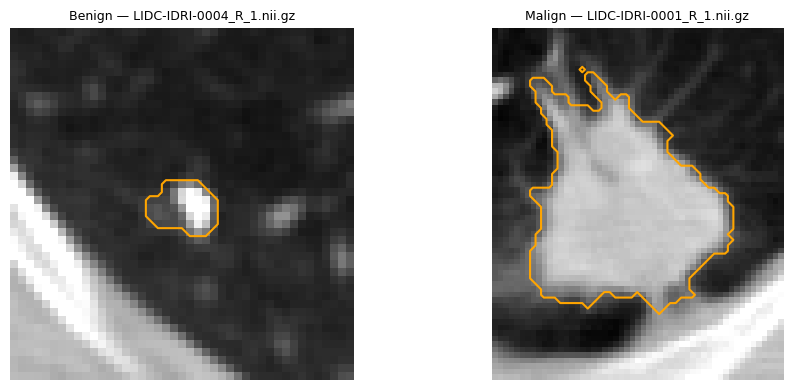

In [5]:
successful = qc.loc[qc['status'].eq('ok')]
display(successful[['native_voxels', 'native_volume_mm3', 'spacing_x', 'spacing_y', 'spacing_z', 'components', 'nonfinite_features']].describe().round(3))
print('Disconnected masks:', int(successful['components'].gt(1).sum()))
print('Planar native ROIs:', int(successful['planar_roi'].fillna(False).sum()))
feature_names = [c for c in features if c.startswith('rad_')]
inventory = pd.Series(feature_names).str.split('_').str[2].value_counts().rename_axis('family').rename('features')
display(inventory.to_frame())
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, diagnosis in zip(axes, ['Benign', 'Malign']):
    candidates = successful.loc[successful['Diagnosis'].eq(diagnosis), 'image']
    if candidates.empty:
        ax.axis('off')
        continue
    filename = candidates.iloc[0]
    image, mask, _ = load_pair(IMAGE_DIR / filename, MASK_DIR / filename)
    values = sitk.GetArrayFromImage(image)
    labels = sitk.GetArrayFromImage(mask)
    z = int(labels.sum(axis=(1, 2)).argmax())
    sx, sy, _ = image.GetSpacing()
    ax.imshow(values[z], cmap='gray', vmin=-1000, vmax=400, aspect=sy / sx)
    ax.contour(labels[z], levels=[0.5], colors='orange')
    ax.set_title(f'{diagnosis} — {filename}', fontsize=9)
    ax.axis('off')
plt.tight_layout()
plt.savefig(OUT / 'example_mask_overlays.png', dpi=150, bbox_inches='tight')
plt.show()

## 6. Continue to modeling

Run **02_malign_benign_modeling.ipynb** next. It joins the feature table with metadata and splits patients before training. No label-based feature selection happens in this notebook.